# Mini-projet Séries Temporelles — TEK-UP 2026

**Modélisation, prévision et diagnostic de la série multidimensionnelle XOM / XLE**

Notebook principal en Python : il reproduit l'étude de bout en bout, sans intervention manuelle autre que l'exécution des cellules.
La logique est dans `src/` ; ce notebook appelle les fonctions et interprète les résultats.

| Partie | Langage |
| --- | --- |
| Sections 1–3 (données, EDA, ARIMA, VAR/VECM, GARCH) | Python **et** R (`notebooks/classical_R.Rmd`) |
| Section 4 (LSTM/GRU, hybride) et extensions | **Python uniquement** |

In [1]:
# Racine du projet retrouvée depuis le dossier courant : le notebook marche lancé
# depuis notebooks/ (Jupyter, nbconvert) comme depuis la racine (VS Code).
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src.utils import load_config, set_seed, print_versions, save_fig, save_table
from src import data

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)

# Seed fixée dès le début : toute la suite (bootstrap, réseaux) devient reproductible.
set_seed()
# Versions affichées en tête : exigence de reproductibilité (cahier §9.1).
print_versions()

python         3.11.9
numpy          1.26.4
pandas         2.2.3
scipy          1.13.1
statsmodels    0.14.4
pmdarima       2.0.4
arch           7.0.0
scikit-learn   1.5.2
tensorflow     2.16.2
prophet        1.1.6
yfinance       0.2.66
matplotlib     3.9.2
seaborn        0.13.2
pyyaml         6.0.2


## 1. Données

### 1.1 Choix de la thématique

Nous retenons l'**option A — Finance** avec le couple **XOM (ExxonMobil) / XLE (Energy Select Sector SPDR ETF)** : une action et son indice sectoriel partagent un facteur commun, ce qui permet d'étudier cointégration et volatilité conditionnelle sur des épisodes de crise identifiables (krach pétrolier 2016, COVID 2020, guerre en Ukraine 2022).
Le **Brent** (`BZ=F`, contrat à terme ICE) est récupéré comme variable exogène pour les extensions (section 7).

Tous les paramètres sont lus dans `config.yaml` :

In [2]:
cfg = load_config()
pd.Series({
    "Source": cfg["data"]["source"],
    "Tickers": ", ".join(cfg["data"]["tickers"].values()),
    "Variable de prix": cfg["data"]["price_column"],
    "Période": f'{cfg["data"]["start"]} → {cfg["data"]["end"]} (incluse)',
    "Fréquence": "journalière, jours de bourse",
    "Split train": cfg["split"]["train_ratio"],
    "Seed": cfg["seed"],
}, name="paramètre").to_frame()

,paramètre
Source,Yahoo Finance
Tickers,"XOM, XLE, BZ=F"
Variable de prix,Adj Close
Période,2016-01-01 → 2025-12-31 (incluse)
Fréquence,"journalière, jours de bourse"
Split train,0.9000
Seed,42


### 1.2 Import des données

`data.load_raw()` lit d'abord le cache `data/raw/*.csv` et ne télécharge depuis Yahoo Finance (`yfinance`, `auto_adjust=False`) que si le fichier est absent.
Ce choix est essentiel pour la reproductibilité : Yahoo **recalcule l'`Adj Close` rétroactivement** à chaque nouveau dividende, si bien qu'un téléchargement fait un autre jour donnerait des prix ajustés légèrement différents. Le cache versionné fige l'échantillon étudié.
Pour forcer un nouveau téléchargement : `data.load_raw(refresh=True)`.

In [3]:
raw = data.load_raw()
for role, df in raw.items():
    print(f"{role:<10} {cfg['data']['tickers'][role]:<5} {df.shape[0]} lignes × {df.shape[1]} colonnes")

target     XOM   2514 lignes × 6 colonnes
sector     XLE   2514 lignes × 6 colonnes
exogenous  BZ=F  2515 lignes × 6 colonnes


### 1.3 Aperçu des données brutes

In [4]:
# Premières et dernières lignes de XOM : vérifie les bornes de la période et la cohérence des colonnes.
pd.concat([raw["target"].head(), raw["target"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,77.5000,77.9400,76.4600,77.4600,49.0023,20400100
2016-01-05,77.1900,78.1400,76.9200,78.1200,49.4198,11993500
2016-01-06,76.6400,77.6400,76.5900,77.4700,49.0086,18826900
2016-01-07,76.0600,77.9900,75.9000,76.2300,48.2242,21263800
2016-01-08,76.3500,76.6500,74.5000,74.6900,47.2500,19033600
2025-12-24,119.3300,120.0500,119.1200,119.2200,116.8754,6137400
2025-12-26,118.8900,119.5500,118.5300,119.1100,116.7676,8066100
2025-12-29,120.1500,121.3000,119.4000,120.5300,118.1596,14782500
2025-12-30,121.1000,121.8000,120.6300,120.9900,118.6106,11150500


In [5]:
pd.concat([raw["sector"].head(), raw["sector"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,30.0800,30.3900,29.6500,30.1500,19.6958,43617400
2016-01-05,30.1300,30.3000,29.7950,30.2650,19.7709,31058400
2016-01-06,29.5500,29.6100,28.8550,29.1000,19.0099,53924200
2016-01-07,28.5350,29.1900,28.2700,28.3900,18.5461,56163800
2016-01-08,28.6300,28.6950,27.9200,28.0250,18.3076,38454200
2025-12-24,44.4200,44.5600,44.3100,44.3700,43.5077,11293900
2025-12-26,44.3200,44.4400,43.9900,44.2000,43.3410,17884500
2025-12-29,44.5100,44.7400,44.2900,44.6200,43.7529,31352100
2025-12-30,44.8000,45.0900,44.8000,44.9600,44.0863,18654700


In [6]:
pd.concat([raw["exogenous"].head(), raw["exogenous"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,37.4000,38.9900,36.7800,37.2200,37.2200,41288
2016-01-05,37.3200,37.5700,36.2500,36.4200,36.4200,29327
2016-01-06,36.7200,36.7200,34.1400,34.2300,34.2300,43019
2016-01-07,34.5200,34.7300,32.1800,33.7500,33.7500,44381
2016-01-08,33.8000,34.7300,32.7900,33.5500,33.5500,39985
2025-12-24,62.4300,62.7200,62.0200,62.2400,62.2400,14966
2025-12-26,62.3500,62.6900,60.5900,60.6400,60.6400,9687
2025-12-29,61.0400,62.1500,60.9500,61.9400,61.9400,9170
2025-12-30,61.7000,62.3300,61.5100,61.9200,61.9200,30567


**Ajustements appliqués par le fournisseur.** Sur Yahoo Finance, `Close` est déjà ajusté des **splits** ; `Adj Close` l'est en plus des **dividendes** (réinvestis). C'est donc `Adj Close` qui mesure le rendement total réellement obtenu par un investisseur, et c'est la variable retenue.
L'écart entre les deux colonnes se lit sur la première ligne de XOM : `Close` = 77,46 $ contre `Adj Close` = 49,00 $ le 2016-01-04, soit dix ans de dividendes cumulés réintégrés dans l'historique. Sur la dernière ligne (2025-12-31), l'écart n'est plus que de 120,34 $ contre 117,97 $ : l'ajustement diminue quand on se rapproche de la date de téléchargement.
Pour le Brent (contrat à terme), il n'y a pas de dividende : `Close` et `Adj Close` sont identiques. La série `BZ=F` raccorde des contrats successifs (échéance la plus proche) : un changement de contrat peut créer un petit saut de prix qui n'est pas un vrai rendement. C'est sans conséquence pour les sections 2 à 6, où le Brent n'intervient pas, et sera rappelé dans la section 7.

### 1.4 Valeurs manquantes et alignement des calendriers

In [7]:
miss = data.missing_report(raw)
save_table(miss, "tab01_manquants")
miss.T

rôle,target,sector,exogenous
ticker,XOM,XLE,BZ=F
début,2016-01-04,2016-01-04,2016-01-04
fin,2025-12-31,2025-12-31,2025-12-31
observations,2514,2514,2515
NaN Adj Close,0,0,0
NaN toutes colonnes,0,0,0
dates dupliquées,0,0,0
jours communs XOM/XLE absents,0,0,2
jours en plus du calendrier commun,0,0,3


In [8]:
# Jours précis où les calendriers diffèrent : on vérifie qu'il s'agit de jours fériés, pas d'erreurs.
common = raw["target"].index.intersection(raw["sector"].index)
brent = raw["exogenous"].index
print("Jours de bourse XOM/XLE sans cotation du Brent :", [d.date() for d in common.difference(brent)])
print("Cotations du Brent hors calendrier XOM/XLE     :", [d.date() for d in brent.difference(common)])

Jours de bourse XOM/XLE sans cotation du Brent : [datetime.date(2016, 10, 10), datetime.date(2016, 11, 11)]
Cotations du Brent hors calendrier XOM/XLE     : [datetime.date(2023, 11, 23), datetime.date(2025, 1, 9), datetime.date(2025, 7, 4)]


**Interprétation.**
- XOM et XLE ont exactement le même calendrier : **2 514 jours de bourse** du 2016-01-04 au 2025-12-31, sans aucune valeur manquante ni date dupliquée. La jointure interne ne supprime donc aucune observation.
- Le Brent cote sur ICE, avec un calendrier un peu différent :
  - il **manque 2 jours** de bourse américains (10 octobre et 11 novembre 2016) ;
  - il a **3 cotations en plus** les jours de fermeture de New York (Thanksgiving 2023, 9 janvier 2025 — journée de deuil national pour Jimmy Carter — et 4 juillet 2025).
- Le Brent est rattaché au calendrier XOM/XLE par jointure à gauche : les 3 jours en plus sont écartés, les 2 jours absents restent `NaN`.

**Pourquoi pas de remplissage (`ffill`) ?** Le calendrier boursier est irrégulier par nature (week-ends, jours fériés). Recopier le prix de la veille créerait des rendements **exactement nuls** qui n'ont jamais existé : ils réduiraient artificiellement la variance et biaiseraient l'estimation des modèles GARCH. Les modèles reçoivent donc la suite des jours de bourse comme un index positionnel ; les dates ne servent qu'aux graphiques et à l'interprétation.
Les 2 `NaN` du Brent ne concernent que la variable exogène, utilisée seulement en section 7 : ils seront traités à ce moment-là (suppression des 2 jours dans le modèle concerné).

### 1.5 Variables dérivées

`data.build_features()` construit, pour chaque actif, le log-prix, le log-rendement en %, la volatilité réalisée sur 21 jours annualisée et la moyenne mobile 50 jours (indicateurs techniques exigés par le cahier §1.1).
Toutes les fenêtres glissantes ne regardent que le passé : la valeur à la date *t* n'utilise que des données jusqu'à *t*, ce qui exclut toute fuite d'information du test vers le train.

In [9]:
var_table = data.variables_table()
save_table(var_table, "tab02_variables", index=False)
# Affichage sans troncature : les définitions sont reprises telles quelles dans le rapport.
var_table.style.hide(axis="index").set_properties(**{"text-align": "left"})

variable,rôle,définition,unité
XOM_price,target,"Prix de clôture ajusté (dividendes, splits) de XOM",USD
XOM_logp,target,Log-prix l_t = ln(P_t),log(USD)
XOM_ret,target,Log-rendement r_t = 100 × ln(P_t / P_{t-1}),%
XOM_vol21,target,Volatilité réalisée : √252 × écart-type glissant de r_t sur 21 jours,% annualisé
XOM_ma50,target,Moyenne mobile de P_t sur 50 jours,USD
XLE_price,sector,"Prix de clôture ajusté (dividendes, splits) de XLE",USD
XLE_logp,sector,Log-prix l_t = ln(P_t),log(USD)
XLE_ret,sector,Log-rendement r_t = 100 × ln(P_t / P_{t-1}),%
XLE_vol21,sector,Volatilité réalisée : √252 × écart-type glissant de r_t sur 21 jours,% annualisé
XLE_ma50,sector,Moyenne mobile de P_t sur 50 jours,USD


In [10]:
panel = data.build_features(data.align_prices(raw))
print(f"Panel : {panel.shape[0]} dates × {panel.shape[1]} variables, "
      f"du {panel.index.min().date()} au {panel.index.max().date()}")
print(f"Type d'index : {type(panel.index).__name__}")
# Fréquence : jours ouvrés théoriques vs jours de bourse réels (les fériés manquent).
bdays = pd.bdate_range(panel.index.min(), panel.index.max())
print(f"Fréquence déclarée : jours de bourse (config.yaml : '{cfg['data']['frequency']}')")
print(f"Jours ouvrés théoriques : {len(bdays)} ; jours de bourse réels : {len(panel)} ; "
      f"jours fériés de bourse : {len(bdays.difference(panel.index))}")
panel.head(3)

Panel : 2514 dates × 15 variables, du 2016-01-04 au 2025-12-31
Type d'index : DatetimeIndex
Fréquence déclarée : jours de bourse (config.yaml : 'B')
Jours ouvrés théoriques : 2608 ; jours de bourse réels : 2514 ; jours fériés de bourse : 94


,XOM_price,XOM_logp,XOM_ret,XOM_vol21,XOM_ma50,XLE_price,XLE_logp,XLE_ret,XLE_vol21,XLE_ma50,BZ=F_price,BZ=F_logp,BZ=F_ret,BZ=F_vol21,BZ=F_ma50
Date,,,,,,,,,,,,,,,
2016-01-04,49.0023,3.8919,NaN,NaN,NaN,19.6958,2.9804,NaN,NaN,NaN,37.2200,3.6168,NaN,NaN,NaN
2016-01-05,49.4198,3.9004,0.8484,NaN,NaN,19.7709,2.9842,0.3807,NaN,NaN,36.4200,3.5951,-2.1728,NaN,NaN
2016-01-06,49.0086,3.8920,-0.8355,NaN,NaN,19.0099,2.9450,-3.9254,NaN,NaN,34.2300,3.5331,-6.2016,NaN,NaN


**Fréquence de la série.** La série est journalière au rythme des **jours de bourse** du NYSE. On ne fixe pas `freq="B"` sur l'index pandas : cela réinsérerait les jours fériés de bourse (Thanksgiving, Noël, etc.) sous forme de lignes vides, qu'il faudrait ensuite remplir artificiellement — exactement ce qu'on a écarté plus haut.
L'index reste donc un `DatetimeIndex` des dates réellement cotées. La fréquence est déclarée dans `config.yaml` et rappelée aux modèles : par exemple la saisonnalité hebdomadaire testée en SARIMA aura s = 5 jours de bourse, et l'annualisation de la volatilité se fait avec 252 jours.

In [11]:
# NaN attendus en début de série (fenêtres glissantes) : à distinguer de vrais manquants.
na = panel.isna().sum().rename("NaN").to_frame()
na["origine"] = ["aucun" if n == 0 else "" for n in na["NaN"]]
w, m = cfg["features"]["realized_vol_window"], cfg["features"]["moving_average_window"]
for c in na.index:
    if c.startswith(("XOM", "XLE")):
        na.loc[c, "origine"] = {"_ret": "1er jour (pas de veille)", "_vol21": f"{w} premiers jours (fenêtre)",
                                "_ma50": f"{m - 1} premiers jours (fenêtre)"}.get(c[c.index("_"):], "aucun")
    elif c.endswith(("_price", "_logp")):
        na.loc[c, "origine"] = "2 jours sans cotation du Brent"
    else:
        na.loc[c, "origine"] = "début de série + 2 jours sans cotation du Brent, propagés par la fenêtre"
na

,NaN,origine
XOM_price,0,aucun
XOM_logp,0,aucun
XOM_ret,1,1er jour (pas de veille)
XOM_vol21,21,21 premiers jours (fenêtre)
XOM_ma50,49,49 premiers jours (fenêtre)
XLE_price,0,aucun
XLE_logp,0,aucun
XLE_ret,1,1er jour (pas de veille)
XLE_vol21,21,21 premiers jours (fenêtre)
XLE_ma50,49,49 premiers jours (fenêtre)


**Lecture.** Pour XOM et XLE, les `NaN` sont uniquement mécaniques : 1 pour le rendement (pas de veille le premier jour), 21 pour la volatilité réalisée (le premier écart-type sur 21 rendements n'est disponible qu'au 22ᵉ jour) et 49 pour la moyenne mobile 50 jours.
Pour le Brent, chacun des 2 jours absents se propage : il manque 2 prix, mais 5 rendements (le jour absent et le lendemain, plus le premier jour), et davantage pour les variables fenêtrées.

### 1.6 Découpage chronologique train / test (90 / 10)

La coupure se fait sur l'ordre des dates, jamais par tirage aléatoire : le test doit être strictement postérieur au train, comme dans une vraie situation de prévision. Toute normalisation (section 4) sera ajustée sur le train uniquement.

In [12]:
train, test = data.train_test_split_time(panel)
split = pd.DataFrame({
    "observations": [len(train), len(test)],
    "part": [len(train) / len(panel), len(test) / len(panel)],
    "début": [train.index.min().date(), test.index.min().date()],
    "fin": [train.index.max().date(), test.index.max().date()],
}, index=["train", "test"])
save_table(split, "tab03_split")

# Sauvegarde des séries préparées : les sections suivantes et le notebook R repartent de ces fichiers.
_ = data.prepare(save=True)
split

,observations,part,début,fin
train,2262,0.8998,2016-01-04,2024-12-27
test,252,0.1002,2024-12-30,2025-12-31


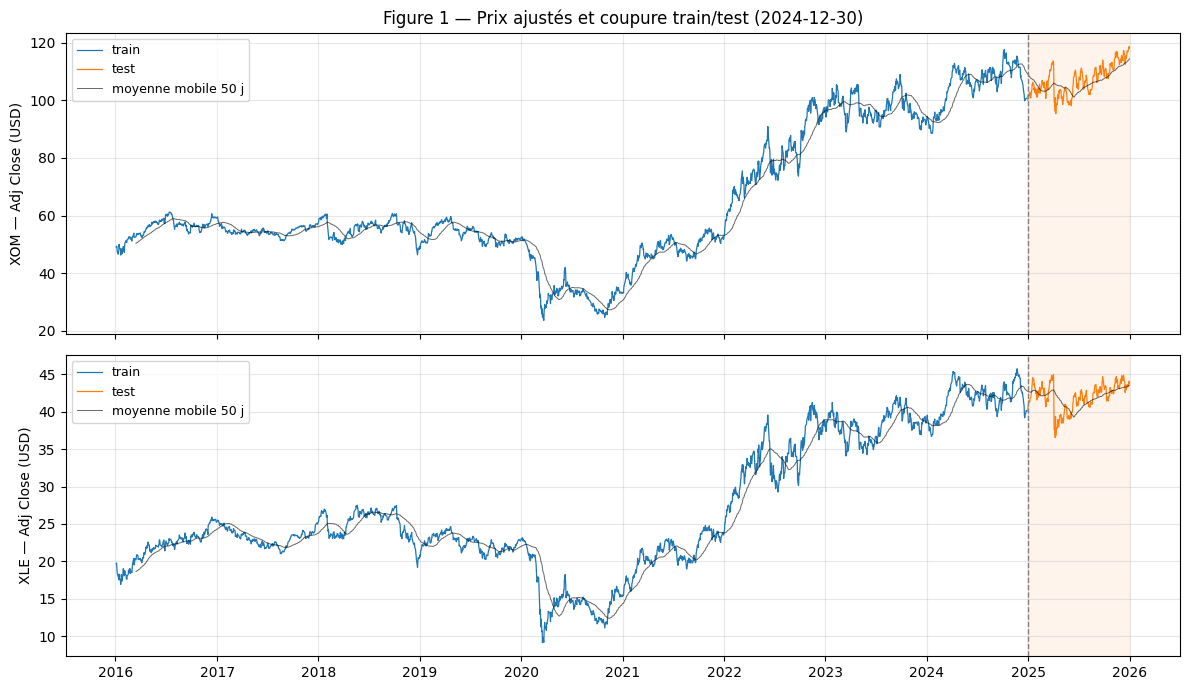

In [13]:
cut = test.index[0]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, tk in zip(axes, ["XOM", "XLE"]):
    ax.plot(train.index, train[f"{tk}_price"], color="tab:blue", lw=0.9, label="train")
    ax.plot(test.index, test[f"{tk}_price"], color="tab:orange", lw=0.9, label="test")
    ax.plot(panel.index, panel[f"{tk}_ma50"], color="black", lw=0.7, alpha=0.6, label="moyenne mobile 50 j")
    ax.axvspan(cut, panel.index[-1], color="tab:orange", alpha=0.08)
    ax.axvline(cut, color="grey", ls="--", lw=1)
    ax.set_ylabel(f"{tk} — Adj Close (USD)")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.3)
axes[0].set_title(f"Figure 1 — Prix ajustés et coupure train/test ({cut.date()})")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save_fig(fig, 1, "prix_train_test")
plt.show()

**Interprétation de la figure 1.**
- **Découpage.** Le train couvre **2 262 jours** (2016-01-04 → 2024-12-27), le test les **252 jours suivants** (2024-12-30 → 2025-12-31), soit environ une année de bourse complète.
- **Évolution des prix.** Les deux séries suivent la même trajectoire générale, avec deux ruptures nettes :
  - l'effondrement de 2020 (COVID, chute de la demande de pétrole) ;
  - la forte hausse de 2021–2022 (reprise puis guerre en Ukraine).

  Le parallélisme visuel entre XOM et XLE (corrélation des rendements journaliers : 0,914 sur toute la période) motive le test de cointégration de la section 3.2.
- **Conséquence pour la modélisation.** Le niveau des prix n'est manifestement pas stationnaire (tendance et ruptures). Les tests ADF/KPSS de la section 2 vérifieront formellement l'ordre d'intégration.
- **Point de vigilance : le test est plus calme que le train.** Le test contient bien un choc (chute brutale début avril 2025, visible sur les deux actifs), mais il est d'une ampleur sans commune mesure avec 2020 :

  | | Train | Test |
  | --- | --- | --- |
  | Écart-type des rendements XOM | 1,78 % | 1,48 % |
  | Volatilité réalisée maximale XOM | 108,9 % | 47,4 % |
  | Volatilité réalisée maximale XLE | 149,9 % | 61,1 % |

  Les erreurs de prévision mesurées sur le test seront donc conditionnelles à ce régime et ne se généraliseront pas automatiquement à une période de crise. On en tiendra compte dans la discussion des limites.